In [9]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from tqdm import tqdm
from snf.farfield import load_far_field, ff_to_T, T_to_R, nf_from_T
from snf.fields import load_field, grid_axes, rotate_by_angles, s21_reciprocity, load_hfss_s21
from snf.swe import psi, j_index
from snf.sampling import full_sampling, add_chi

DATA = '../data/'

# Define Setup

In [2]:
freq = 15 * 10**9
k = 2 * np.pi * freq / scipy.constants.c
R_PROBE = 0.4 # Distance from AUT origin to probe far field origin (m)
r0 = 0.095 # AUT minimum sphere radius (m)
S11_probe_dB = -0.999930 # Probe S11 at 15 GHz

N_AUT = 40 # ~ k r0 + 10
N_PROBE = 12
print(f'k r0 = {k * r0:.1f}')

probe_wp = 1
aut_wp = 1

k r0 = 29.9


# Calculate Official SWEC from Far Field

In [3]:
ff_probe = load_far_field(DATA + f'FF_fields/FF_probe_wp{probe_wp}.csv')
T_probe = ff_to_T(*ff_probe, N_PROBE)
R_probe = T_to_R(T_probe)

ff_aut = load_far_field(DATA + f'FF_fields/FF_AUT_wp{aut_wp}.csv')
T_aut = ff_to_T(*ff_aut, N_AUT)

# Forward Calculation: Generate w using Psi

In [ ]:
# test points (theta cut)
theta = np.arange(-180, 180, 10)
phi = 0
chi = 0

In [ ]:
# generate Psi and test forward model with ground truth T_aut
Psi = psi(
    chi=np.full_like(np.radians(theta), np.radians(chi)),
    theta=np.radians(theta),
    phi=np.full_like(np.radians(theta), np.radians(phi)),
    R=R_probe,
    N=N_AUT, 
    kA=k * R_PROBE, 
    Np=N_PROBE,
    mus=np.arange(-3, 3 + 1),# truncation
    weighted=False
)
w_model = (Psi @ T_aut).conj()

In [ ]:
# generate reciprocity points using fields
Ea_path = DATA + f'SNF_fields_ports/probe/wp{probe_wp}/E.csv'
Ha_path = DATA + f'SNF_fields_ports/probe/wp{probe_wp}/H.csv'

Eb_path = DATA + f'SNF_fields_ports/AUT/wp{aut_wp}/E.csv'
Hb_path = DATA + f'SNF_fields_ports/AUT/wp{aut_wp}/H.csv'

xyz, Ea = load_field(Ea_path)
_, Ha = load_field(Ha_path)

_, Eb = load_field(Eb_path)
_, Hb = load_field(Hb_path)

w_recip = np.zeros(len(theta), dtype=complex)
for i, th in enumerate(theta):
    Ea_rot = rotate_by_angles(xyz, Ea, th, phi, chi)
    Ha_rot = rotate_by_angles(xyz, Ha, th, phi, chi)
    w_recip[i] = s21_reciprocity(xyz, Ea_rot, Ha_rot, Eb, Hb)

In [ ]:
# plot comparison

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(theta, 20 * np.log10(np.abs(w_recip)), 'r-', lw=1.5, label='Reciprocity calculated')
ax1.plot(theta, 20 * np.log10(np.abs(w_model)), 'ko', label='Psi model predicted')
ax1.set(xlabel='Probe theta (deg)', ylabel='w (dB)', title=f'Probe wave port {probe_wp}, AUT wave port {aut_wp}: magnitude')

ax2.plot(theta, np.degrees(np.angle(w_recip)), 'r-', lw=1.5, label='Reciprocity calculated')
ax2.plot(theta, np.degrees(np.angle(w_model)), 'ko', label='Psi model predicted')
ax2.set(xlabel='Probe theta (deg)', ylabel='S21 phase (deg)', title=f'Probe wave port {probe_wp}, AUT wave port {aut_wp}: phase', ylim=(-180, 180))

hfss_theta, hfss_db, hfss_phase = load_hfss_s21(DATA + 'S_params.csv', probe_wp, aut_wp)
ax1.plot(hfss_theta, hfss_db, 'bs', mfc='none', label='HFSS')
ax2.plot(hfss_theta, hfss_phase, 'bs', mfc='none', label='HFSS')

for ax in (ax1, ax2):
    ax.grid(True)
    ax.legend()

plt.tight_layout()

# Inverse Problem: Reconstruct T_aut with Reciprocity Theorem

In [4]:
# give full sampling points (in radians)
theta, phi = full_sampling(N_AUT)
chi, theta, phi = add_chi(theta, phi)
print(chi.shape)

(6642,)


In [ ]:
# generate reciprocity points using fields
Ea_path = DATA + f'SNF_fields_ports/probe/wp{probe_wp}/E.csv'
Ha_path = DATA + f'SNF_fields_ports/probe/wp{probe_wp}/H.csv'

Eb_path = DATA + f'SNF_fields_ports/AUT/wp{aut_wp}/E.csv'
Hb_path = DATA + f'SNF_fields_ports/AUT/wp{aut_wp}/H.csv'

xyz, Ea = load_field(Ea_path)
_, Ha = load_field(Ha_path)

_, Eb = load_field(Eb_path)
_, Hb = load_field(Hb_path)

w = np.zeros(len(theta), dtype=complex)
for i, (th, ph, ch) in tqdm(enumerate(zip(theta, phi, chi)), total=len(theta)):
    Ea_rot = rotate_by_angles(xyz, Ea, th, ph, ch, degrees=False)
    Ha_rot = rotate_by_angles(xyz, Ha, th, ph, ch, degrees=False)
    w[i] = s21_reciprocity(xyz, Ea_rot, Ha_rot, Eb, Hb)
np.save(DATA + f'w_full_probe{probe_wp}_aut{aut_wp}.npy', w)

# w = np.load(DATA + f'w_full_probe{probe_wp}_aut{aut_wp}.npy')

100%|██████████| 6642/6642 [34:15<00:00,  3.23it/s]


In [6]:
# generate Psi to set up inverse problem and solve
Psi, sw = psi(
    chi=chi,
    theta=theta,
    phi=phi,
    R=R_probe,
    N=N_AUT, 
    kA=k * R_PROBE, 
    Np=N_PROBE,
    mus=np.arange(-3, 3 + 1), # truncation
    weighted=True
)

# Prepare w with Hansen convention (conjugation, weighting)
w_p = w.conj() * sw

T_aut_pred, residuals, _, _ = np.linalg.lstsq(Psi, w_p, rcond=None)
print(f'Relative coefficient error: {np.linalg.norm(T_aut_pred - T_aut) / np.linalg.norm(T_aut):.4f}')

Relative coefficient error: 0.0026


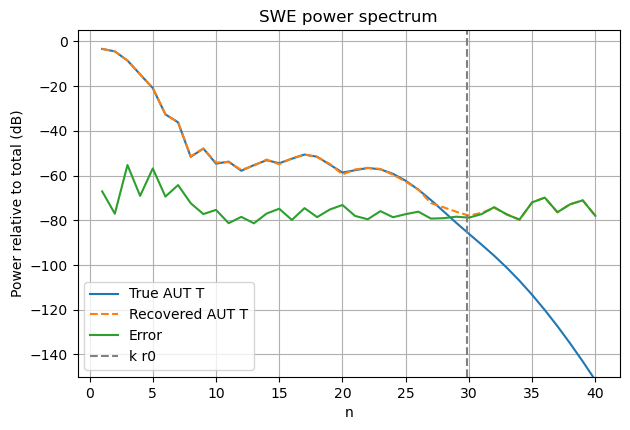

In [11]:
# Power per n: truth, recovered, and error (all relative to total true power)
power_n = lambda T: np.array([np.sum(np.abs(T[j_index(np.array([1, 2])[:, None], np.arange(-n, n + 1)[None], n)])**2) for n in range(1, N_AUT + 1)])
ns, P_tot = np.arange(1, N_AUT + 1), np.sum(np.abs(T_aut)**2)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ns, 10 * np.log10(power_n(T_aut) / P_tot), label='True AUT T')
ax.plot(ns, 10 * np.log10(power_n(T_aut_pred) / P_tot), '--', label='Recovered AUT T')
ax.plot(ns, 10 * np.log10(power_n(T_aut_pred - T_aut) / P_tot), label='Error')
ax.axvline(k * r0, color='gray', ls='--', label='k r0')
ax.set(xlabel='n', ylabel='Power relative to total (dB)', title='SWE power spectrum', ylim=(-150, 5))
ax.grid(True); ax.legend()

# Near Field Cuts from the Recovered T

In [ ]:
# HFSS AUT near field (Eb, Hb) vs the field radiated by the far field T and the recovered T

E_hfss, H_hfss = Eb, Hb
Ts = {'Far field T_aut': T_aut, 'Recovered T (full grid LS)': T_aut_pred}

th_1d, ph_1d, R_sphere = grid_axes(xyz)
nearest = lambda a: np.argmin(np.abs(np.angle(np.exp(1j * (ph_1d - a)))))
grid = np.arange(len(xyz)).reshape(th_1d.size, ph_1d.size)
cuts = {plane: np.r_[grid[::-1, nearest(b)], grid[:, nearest(a)]] for a, b, plane in ((0, np.pi, 'E'), (np.pi / 2, 3 * np.pi / 2, 'H'))}
theta_cut = np.r_[-np.degrees(th_1d[::-1]), np.degrees(th_1d)]
tan = lambda F, idx: F - np.sum(F * xyz[idx], axis=1)[:, None] * xyz[idx] / R_sphere**2

# |F tangential| relative to the HFSS peak of each cut, then the error |F - F_HFSS| on the same scale
for kind in ('field', 'error'):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for row, (field, F_hfss) in enumerate((('E', E_hfss), ('H', H_hfss))):
        for col, (plane, idx) in enumerate(cuts.items()):
            ref = tan(F_hfss[idx].conj(), idx) # HFSS -> Hansen convention
            peak = np.linalg.norm(ref, axis=1).max()
            dB = lambda F: 20 * np.log10(np.linalg.norm(F, axis=1) / peak)
            ax = axes[row, col]
            if kind == 'field':
                ax.plot(theta_cut, dB(ref), 'k-', lw=2, label='HFSS')
            for i, (name, T) in enumerate(Ts.items()):
                F = tan(nf_from_T(T, xyz[idx], k)[row], idx)
                ax.plot(theta_cut, dB(F) if kind == 'field' else dB(F - ref), '--', color=f'C{i}', label=name)
            ax.set(xlabel='Theta (deg)', ylabel='dB rel. HFSS peak', xlim=(-180, 180), ylim=(-50, 5) if kind == 'field' else (-100, -20),
                   title=f'AUT {field}{" error" if kind == "error" else ""} at r = {R_sphere:.2f} m, {plane}-plane')
            ax.grid(True); ax.legend(fontsize=7)
    plt.tight_layout()